# Rooftop solar

The installation of rooftop solar is generally more advantageous in terms of area, obstructions and a more advantageous tilt of the solar panels. There is a specific tool developed by Brussels Environment (Carte solaire) that can be used to have a general idea of the potential energy produced by rooftop solar. 
For example, if I run the BE utility, it informs me that my building has 240 m2 of area with good solar potential. In particular, the tool calculates a profit of 7319 Eur in 10 years with 48 solar panels:
* 8500 kWh annual energy production,
* 15518 Eur price of the installation,
* 9874 Eur received from green certificates,
* 12963 Eur of avoided consumption.

However, the tool assumes an energy consumption of around 2000 kWh per year (average consumption in Brussels), while my building contains 16 apartments and thus has a much higher global consumption. It is possible to modify a bit the calculation parameters, but not that much.
We can perform the same calculations we did for the balcony setup using pvlib.
For my calculation, I have assumed the following setup:
24 solar panels
Each solar panel has an area of 2.22 m2 and a peak power output of 500 W
The overall efficiency is 85%
The panels are facing SW (223 degrees)
They are tilted at the optimal angle of 33 degrees

Given these specifications, the yearly production of energy from the solar panels fluctuates around 11 MWh and 12.4 MWh. 



In [5]:
# Compute production

import numpy as np
import pandas as pd
import pvlib
from pvlib.iotools import get_pvgis_hourly
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

lat, lon, alt = 50.817205, 4.377434, 105.452
azimuth = 223          # vertical, south-facing (pvlib: 180 = south)
tz = "Europe/Brussels"

hz = pd.read_csv("../data/horizon_rooftop.csv")   # adapt column names
hz_az, hz_hg = hz["azimuth"].values, hz["horizon_height"].values

data, meta = get_pvgis_hourly(
    latitude=lat,
    longitude=lon,
    start=2019,
    end=2023,
    raddatabase="PVGIS-SARAH3",
    components=True,
    surface_azimuth=azimuth,
    usehorizon=False,
    optimalangles=False,
    optimal_surface_tilt=True, 
    map_variables=True,
)
slope = meta["inputs"]["mounting_system"]["fixed"]["slope"]
print(slope)  # {'value': ..., 'optimal': True}
print(slope["value"])

data.index = data.index.tz_convert("Europe/Brussels")

site = pvlib.location.Location(latitude=lat, longitude=lon, tz=tz, altitude=alt)

solpos = site.get_solarposition(data.index)
sun_horizon = np.interp(solpos["azimuth"], hz_az, hz_hg, period=360)
blocked = (solpos["apparent_elevation"] <= sun_horizon)
data["poa_direct_corr"] = data["poa_direct"].where(~blocked, 0.0)

h = np.radians(hz_hg)
diff = ((hz_az - azimuth + 180) % 360) - 180
front = np.abs(diff) <= 90
weights = np.cos(np.radians(diff[front]))

svf = np.sum(weights * np.cos(h[front])**2) / np.sum(weights)

data['poa_diffuse'] = svf*data['poa_sky_diffuse'] + data['poa_ground_diffuse']
data['poa_global'] = data['poa_direct_corr'] + data['poa_diffuse']

data = data.iloc[:-1]


{'value': 33, 'optimal': True}
33


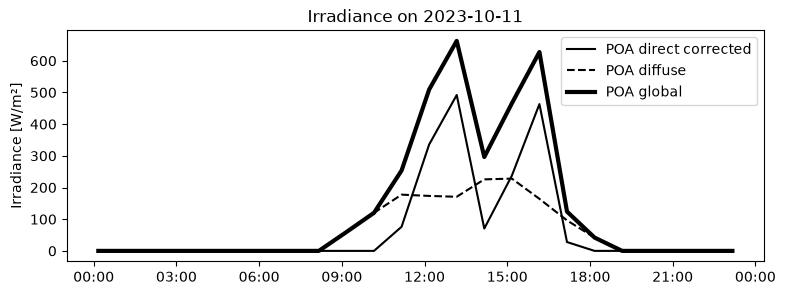

In [6]:
day = "2023-10-11"
day_end = "2023-10-11 23:59"

fig, ax = plt.subplots(figsize=(9,3))
ax.plot(data["poa_direct_corr"].loc[day], label="POA direct corrected", c='k')
ax.plot(data["poa_diffuse"].loc[day], label="POA diffuse", c='k', ls='--')
ax.plot(data["poa_global"].loc[day], label="POA global", c ='k', lw=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=tz))
ax.set_ylabel("Irradiance [W/m²]")
ax.set_title(f"Irradiance on {day}")
ax.legend()
ax.grid(False)

plt.show()


If we compare with the irradiance collected by the balcony solar panel, we can see that the rooftop solar panel can intercept also the afternoon light (15:00-18:00), which is blocked by the buildings for the balcony solar panel.

In [7]:
# Power output
from pvlib.temperature import sapm_cell
temp_cell = sapm_cell(
    poa_global=data["poa_global"],
    temp_air=data["temp_air"],
    wind_speed=data["wind_speed"],
    a=-3.56,
    b=-0.075,
    deltaT=3
)

n_panels = 24
length = 1.96  #m
height = 1.134  #m
area = n_panels * length * height #m2
eta_panel = 0.225
eta_sys = 0.85
P_nom = n_panels * 500 #W
price = 16000  #Eur

gamma = -0.0035  # 1/°C
power = (data["poa_global"]* P_nom/1000 * (1 + gamma*(temp_cell - 25)))

data['P_prod'] = power * eta_sys  #W
data['E_prod'] = data['P_prod']/1000  # kWh

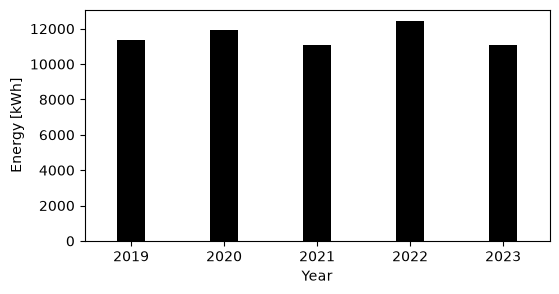

Average yearly production: 11579.44 kWh/year


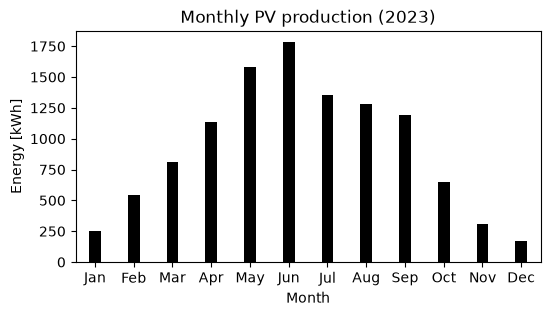

In [9]:
yearly = data['E_prod'].resample("YE").sum()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(yearly.index.year, yearly.values, width=0.3, color='black')
ax.set_xlabel("Year")
ax.set_xlim(2018.5, 2023.5)
ax.set_ylabel("Energy [kWh]")
plt.show()

average_yearly = yearly.mean()
print(f"Average yearly production: {average_yearly:.2f} kWh/year")

monthly_2023 = (data.loc["2023", "E_prod"].resample("ME").sum())
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(monthly_2023.index.month, monthly_2023.values, width=0.3, color='black')
ax.set_xlabel("Month")
ax.set_xlim(0.5, 12.5)
ax.set_ylabel("Energy [kWh]")
ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Monthly PV production (2023)")
plt.show()

If we assume the energy cost to be around 0.3 Eur kWh, this would correspond to a saving of around 21473.36 Eur, which is much more than the one predicted by the Carte Solaire, probably due to the much larger production of energy predicted by pvlib, and the assumed energy cost. Assuming a price of 0.05 Eur/kWh, the amount of electricity sold to the market corresponds to 2210.82 Eur. 

On top of this, we need to consider the money collected by selling green certificates. Green certificates are a mechanism to support the production of renewable energy: each year, suppliers of energy (like Engie, Luminus, TotalEnergies, etc.) are forced to buy a quota of green certificates set by the market regulator BRUGEL. These green certificates are awarded by BRUGEL to the producers of green energy from solar panels. The price of green certificates is assigned with an offer/demand logic through a public market, but it has a minimum guaranteed price of 65 Eur. Technically, a green certificate is granted every time an emission of 217 kg of CO2 is avoided.
The installation needs to be certified to be eligible for green certificates, after that it has the right to claim green certificates for 10 years.


## How many green certificates can we get?
For photovoltaic panels, 1.81 green certificates are granted for each MWh produced. However, this rate is modified depending on the peak installed power. In our case, the rate is actually 1.739 green certificates per MWh. With an average of around 11.5 MWh per year, we should get 20.14 green certificates per year, corresponding to a minimum of 1308.88 Eur/year, or 13088.82 Eur in 10 years. The minimum is what we would get if we sold all the certificates to Elia at the minimum price of 65 Eur/CV. However, in the last 2 years the average price on the market has been a bit higher at around 70 Eur/CV, which would give us 14095.65 Eur in 10 years. 



## Energy sharing
Let’s say that we manage to agree on investing in rooftop solar, and we end up installing 12 kW of solar panels. Once the panels start producing energy, this energy then needs to be redistributed among the people living in the building.
There are 3 ways of energy sharing that are envisaged by the Brussels authorities:
Sharing energy between two people,
Sharing energy in a single building,
Sharing energy across multiple buildings. 

The second option is the most interesting in my case, so let’s focus on the energy sharing in a single building. 
As outlined by BE, the first step is to contact Sibelga and introduce a smart meter request for all the apartments in the building. Smart meters are essential to apply any type of repartition logic.

The second step is to select a way to repartition the energy. The choice is between:
* Fixed repartition (based on the number of apartments or weighted by the initial investment)
    * This can be fixed with a single repartition round, or multiple repartition rounds. With multiple repartition rounds, the idea is that the energy surplus is redistributed for the consumers that still need to cover their energy consumption after the previous round. This way, it is possible to reduce the injection.

* Prorata repartition: each consumer gets a share of the energy produced based on the percentage of the total energy that they are consuming at that moment (every 15 minutes)
* Hybrid repartition: first round is fixed, second round is prorata.

Sibelga can also accept customized methods for repartition. 
The objective of the repartition methodology is to match production with consumption as much as possible while fairly redistributing the profits. The fixed repartition is the most fair, but the less efficient leading to a greater grid injection. The prorata is the most efficient but less fair if there is a great imbalance between the consumption. The fixed repartition with multiple rounds and the hybrid repartition propose a balance between the two. 

The third step is to sign a document to fix the energy price. Bruxelles Environment says that it offers an excel file to compute the optimal energy price but I wasn’t able to find it.
The last step is to introduce an energy sharing form at Sibelga. 

Another option is to simply contact an investor and share the roof of the building. The investor will take care of installing the solar panel, while the owner(s) of the building will collect a rent that is negotiated with the investor. 
